# BÀI THỰC HÀNH 3.3: ĐÁNH GIÁ VÀ SO SÁNH 10 MÔ HÌNH PHÂN LOẠI TRÊN TẬP DỮ LIỆU DIGITS
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


## 1. Nạp tập dữ liệu Digits, tiền xử lý và khởi tạo danh sách 10 mô hình phân loại (theo Bài 3.1)


In [1]:
# ==============================================================================
# BƯỚC 1: NẠP DỮ LIỆU DIGITS VÀ KHỞI TẠO 10 THUẬT TOÁN PHÂN LOẠI CỦA BÀI 3.1
# ==============================================================================

# Import các thư viện toán học, xử lý dữ liệu và vẽ đồ thị
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Import tập dữ liệu nhận diện chữ số viết tay (Digits dataset)
from sklearn import datasets
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

# Import 10 thuật toán phân loại tương ứng trong Bài 3.1
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Nạp dữ liệu đặc trưng X và nhãn mục tiêu y
X_digits, y_digits = datasets.load_digits(return_X_y=True)

# 2. Tiền xử lý: Chuẩn hóa chia tỷ lệ giá trị pixel về khoảng [0, 1]
X_digits = X_digits / X_digits.max()

# 3. Phân chia tập dữ liệu: 90% tập Huấn luyện (Train) và 10% tập Kiểm thử (Test)
n_samples = len(X_digits)
split_idx = int(0.9 * n_samples)

X_train = X_digits[:split_idx]
y_train = y_digits[:split_idx]
X_test = X_digits[split_idx:]
y_test = y_digits[split_idx:]

print("=== THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU DIGITS ===")
print(f"Tổng số mẫu dữ liệu:              {n_samples} mẫu (64 thuộc tính pixel)")
print(f"Số mẫu tập Huấn luyện (Train 90%): {len(X_train)} mẫu (Shape: {X_train.shape})")
print(f"Số mẫu tập Kiểm thử (Test 10%):    {len(X_test)} mẫu (Shape: {X_test.shape})")

# 4. Danh sách tên gọi của 10 mô hình phân loại (theo đúng Bài 3.1)
names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

# 5. Khởi tạo danh sách 10 đối tượng mô hình với các tham số tương ứng từ Bài 3.1
classifiers = [
    KNeighborsClassifier(3),                                                               # K-NN với k=3 láng giềng
    SVC(kernel="linear", C=0.025, random_state=42),                                       # Linear SVM với C=0.025
    SVC(gamma=2, C=1, random_state=42),                                                    # RBF SVM với gamma=2, C=1
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),                            # Quá trình Gauss với RBF kernel
    DecisionTreeClassifier(max_depth=5, random_state=42),                                  # Cây quyết định độ sâu tối đa 5
    RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1, random_state=42), # Rừng ngẫu nhiên 10 cây
    MLPClassifier(alpha=1, max_iter=1000, random_state=42),                               # Mạng nơ-ron nhiều lớp MLP
    AdaBoostClassifier(random_state=42),                                                   # Thuật toán tập hợp AdaBoost
    GaussianNB(),                                                                          # Naive Bayes phân phối chuẩn
    QuadraticDiscriminantAnalysis(reg_param=0.3, tol=1e-3),                                # Phân tích biệt thức bậc hai QDA với reg_param tránh ma trận kỳ dị
]

print(f"\nĐã khởi tạo thành công {len(classifiers)} mô hình phân loại!")


=== THÔNG TIN PHÂN CHIA TẬP DỮ LIỆU DIGITS ===
Tổng số mẫu dữ liệu:              1797 mẫu (64 thuộc tính pixel)
Số mẫu tập Huấn luyện (Train 90%): 1617 mẫu (Shape: (1617, 64))
Số mẫu tập Kiểm thử (Test 10%):    180 mẫu (Shape: (180, 64))

Đã khởi tạo thành công 10 mô hình phân loại!


## 2. Huấn luyện và Đánh giá hiệu năng của 10 mô hình trên tập kiểm thử Digits


In [2]:
# ==============================================================================
# BƯỚC 2: HUẤN LUYỆN LẦN LƯỢT 10 MÔ HÌNH VÀ TỔNG HỢP CÁC CHỈ SỐ ĐO LƯỜNG
# ==============================================================================

# Khởi tạo các danh sách lưu trữ kết quả đánh giá
results_list = []
trained_models = {}
predictions_dict = {}

print("=== BẮT ĐẦU QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ 10 MÔ HÌNH ===")

# Duyệt qua từng mô hình trong danh sách
for name, clf in zip(names, classifiers):
    # Huấn luyện mô hình trên tập Train (X_train, y_train)
    clf.fit(X_train, y_train)
    
    # Dự đoán nhãn trên tập Test (X_test)
    y_pred = clf.predict(X_test)
    
    # Lưu lại mô hình và dự đoán để phục vụ phân tích ma trận nhầm lẫn
    trained_models[name] = clf
    predictions_dict[name] = y_pred
    
    # Tính toán các chỉ số đánh giá
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
    
    n_correct = int((y_pred == y_test).sum())
    n_wrong = int((y_pred != y_test).sum())
    
    # Lưu kết quả vào danh sách
    results_list.append({
        'Mô hình': name,
        'Accuracy (%)': acc * 100,
        'F1-Macro (%)': f1_macro * 100,
        'F1-Weighted (%)': f1_weighted * 100,
        'Precision-Macro (%)': prec_macro * 100,
        'Recall-Macro (%)': rec_macro * 100,
        'Số mẫu đúng': f"{n_correct}/{len(y_test)}",
        'Số mẫu sai': f"{n_wrong}/{len(y_test)}"
    })
    
    print(f"Hoàn thành: {name:<22} | Accuracy = {acc * 100:6.2f}% | F1-Macro = {f1_macro * 100:6.2f}% | Đúng: {n_correct}/{len(y_test)}")

# Tạo DataFrame tổng hợp kết quả
df_results = pd.DataFrame(results_list)

# Sắp xếp các mô hình theo thứ tự F1-Macro giảm dần (từ tốt nhất đến kém nhất)
df_sorted = df_results.sort_values(by='F1-Macro (%)', ascending=False).reset_index(drop=True)

# Định dạng bảng hiển thị số thập phân 2 chữ số
df_display = df_sorted.copy()
for col in ['Accuracy (%)', 'F1-Macro (%)', 'F1-Weighted (%)', 'Precision-Macro (%)', 'Recall-Macro (%)']:
    df_display[col] = df_display[col].map(lambda x: f"{x:.2f}%")

print("\n=== BẢNG TỔNG HỢP HIỆU NĂNG 10 MÔ HÌNH PHÂN LOẠI (SẮP XẾP THEO F1-MACRO) ===")
print(df_display.to_string(index=False))


=== BẮT ĐẦU QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ 10 MÔ HÌNH ===
Hoàn thành: Nearest Neighbors      | Accuracy =  96.67% | F1-Macro =  96.66% | Đúng: 174/180
Hoàn thành: Linear SVM             | Accuracy =  91.67% | F1-Macro =  91.34% | Đúng: 165/180
Hoàn thành: RBF SVM                | Accuracy =  80.00% | F1-Macro =  83.03% | Đúng: 144/180
Hoàn thành: Gaussian Process       | Accuracy =  96.11% | F1-Macro =  96.00% | Đúng: 173/180
Hoàn thành: Decision Tree          | Accuracy =  61.11% | F1-Macro =  61.42% | Đúng: 110/180
Hoàn thành: Random Forest          | Accuracy =  74.44% | F1-Macro =  73.87% | Đúng: 134/180
Hoàn thành: Neural Net             | Accuracy =  92.78% | F1-Macro =  92.51% | Đúng: 167/180
Hoàn thành: AdaBoost               | Accuracy =  71.67% | F1-Macro =  72.35% | Đúng: 129/180
Hoàn thành: Naive Bayes            | Accuracy =  81.11% | F1-Macro =  81.42% | Đúng: 146/180
Hoàn thành: QDA                    | Accuracy =  92.22% | F1-Macro =  92.11% | Đúng: 166/180

=== BẢNG 

## 3. Trực quan hóa Biểu đồ so sánh hiệu năng 10 mô hình phân loại


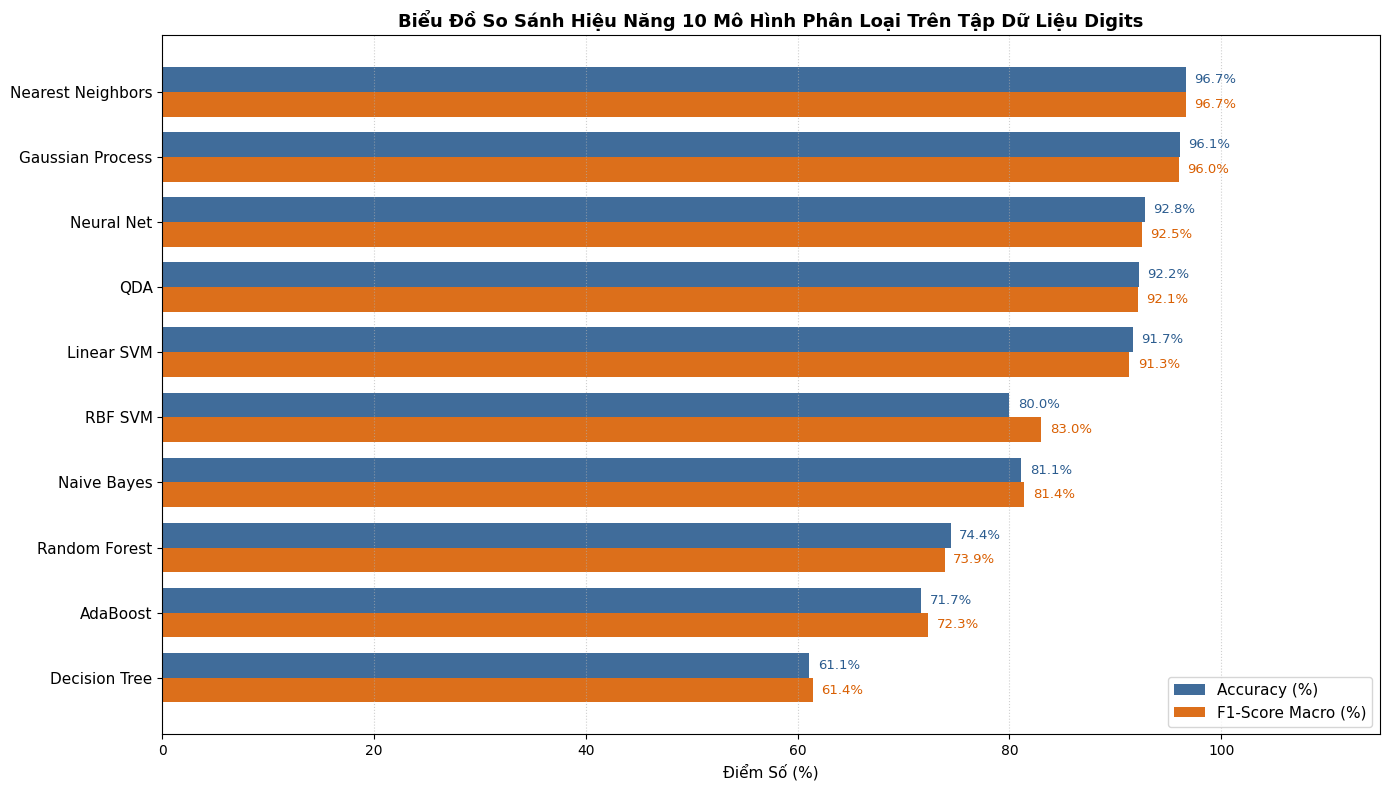

In [3]:
# ==============================================================================
# BƯỚC 3: VẼ BIỂU ĐỒ CỘT NGANG ĐỐI SÁNH ACCURACY VÀ F1-SCORE CỦA 10 MÔ HÌNH
# ==============================================================================

# Thiết lập kích thước đồ thị
fig, ax = plt.subplots(figsize=(14, 8))

# Lấy dữ liệu tên mô hình và điểm số đã sắp xếp
model_names = df_sorted['Mô hình']
acc_values = df_sorted['Accuracy (%)']
f1_values = df_sorted['F1-Macro (%)']

y_pos = np.arange(len(model_names))
bar_height = 0.38

# Vẽ cột Accuracy (màu xanh dương)
bars_acc = ax.barh(y_pos - bar_height / 2, acc_values, height=bar_height, color='#2b5c8f', label='Accuracy (%)', alpha=0.9)

# Vẽ cột F1-Score (màu cam)
bars_f1 = ax.barh(y_pos + bar_height / 2, f1_values, height=bar_height, color='#d95f02', label='F1-Score Macro (%)', alpha=0.9)

# Ghi chú giá trị phần trăm lên từng thanh cột
for bar in bars_acc:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height() / 2, f'{width:.1f}%', va='center', ha='left', fontsize=9.5, color='#2b5c8f')

for bar in bars_f1:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height() / 2, f'{width:.1f}%', va='center', ha='left', fontsize=9.5, color='#d95f02')

ax.set_yticks(y_pos)
ax.set_yticklabels(model_names, fontsize=11)
ax.invert_yaxis()  # Đưa mô hình có điểm cao nhất lên vị trí trên cùng
ax.set_xlabel('Điểm Số (%)', fontsize=11)
ax.set_xlim(0, 115)  # Mở rộng giới hạn trục x để không bị tràn chữ
ax.set_title('Biểu Đồ So Sánh Hiệu Năng 10 Mô Hình Phân Loại Trên Tập Dữ Liệu Digits', fontsize=13, fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.6)
ax.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()


## 4. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) cho các mô hình tiêu biểu


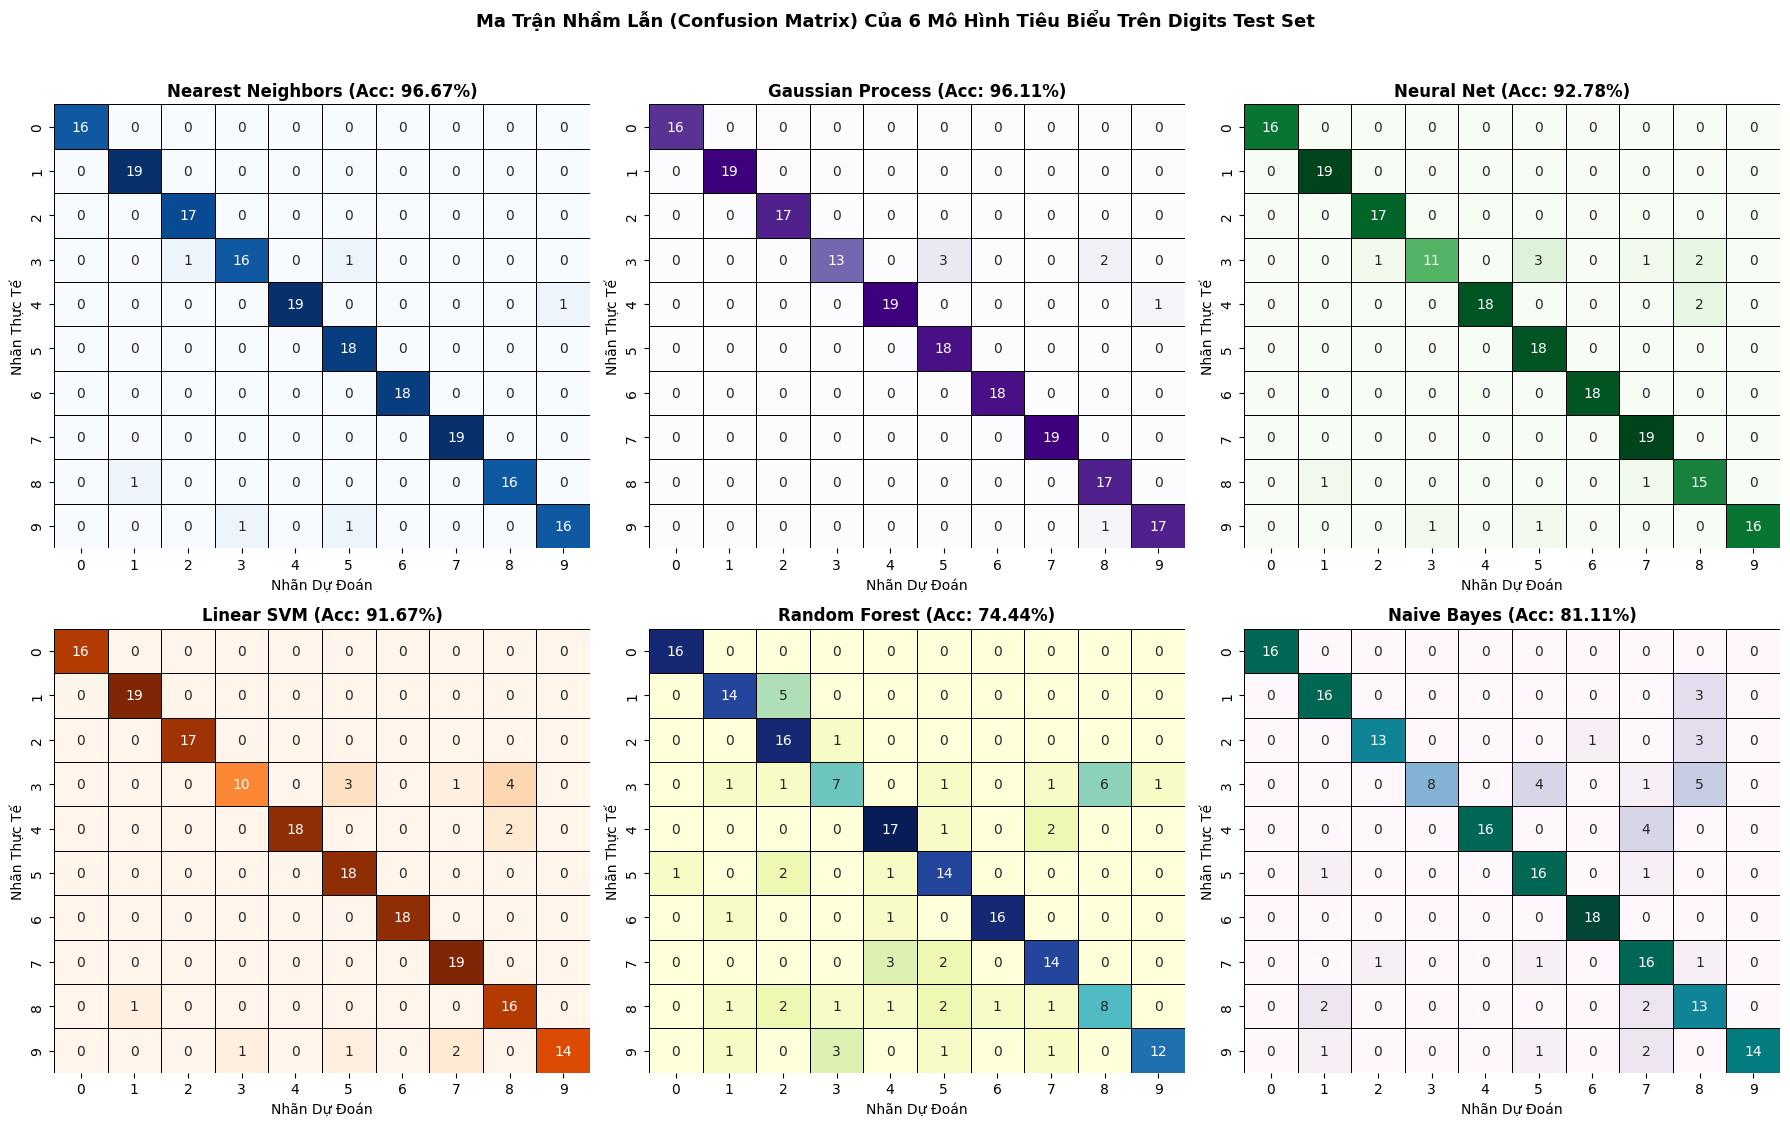

In [4]:
# ==============================================================================
# BƯỚC 4: VẼ MA TRẬN NHẦM LẪN DẠNG LƯỚI CHO 6 MÔ HÌNH ĐẠI DIỆN
# ==============================================================================

# Chọn ra 6 mô hình đại diện gồm: Top 3 mô hình tốt nhất và 3 mô hình thuộc các họ thuật toán khác
selected_models = [
    "Nearest Neighbors",
    "Gaussian Process",
    "Neural Net",
    "Linear SVM",
    "Random Forest",
    "Naive Bayes"
]

# Tạo khung lưới 2 hàng x 3 cột
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes_flat = axes.flatten()

# Bảng màu cho từng ma trận
color_maps = ['Blues', 'Purples', 'Greens', 'Oranges', 'YlGnBu', 'PuBuGn']

# Lần lượt vẽ ma trận nhầm lẫn cho 6 mô hình đã chọn
for idx, (m_name, cmap) in enumerate(zip(selected_models, color_maps)):
    y_pred_m = predictions_dict[m_name]
    cm_m = confusion_matrix(y_test, y_pred_m)
    acc_m = accuracy_score(y_test, y_pred_m)
    
    sns.heatmap(
        cm_m,
        annot=True,
        fmt='d',
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor='black',
        ax=axes_flat[idx]
    )
    axes_flat[idx].set_title(f"{m_name} (Acc: {acc_m * 100:.2f}%)", fontsize=12, fontweight='bold')
    axes_flat[idx].set_xlabel("Nhãn Dự Đoán", fontsize=10)
    axes_flat[idx].set_ylabel("Nhãn Thực Tế", fontsize=10)

plt.suptitle("Ma Trận Nhầm Lẫn (Confusion Matrix) Của 6 Mô Hình Tiêu Biểu Trên Digits Test Set", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Trực quan hóa các mẫu nhận dạng sai của các mô hình hàng đầu (Top Models)


Số mẫu bị cả 3 mô hình hàng đầu (KNN, GP, MLP) dự đoán sai: 3 mẫu (Chỉ số index: [np.int64(41), np.int64(110), np.int64(148)])


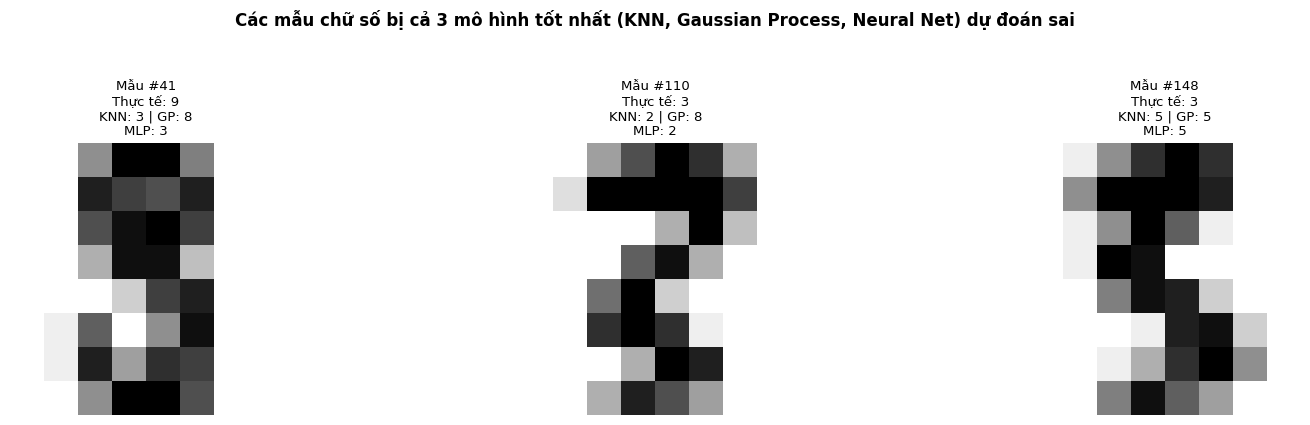


=== BẢNG CHI TIẾT CÁC MẪU SAI CHUNG CỦA TOP 3 MÔ HÌNH ===
Mẫu index #41  | Nhãn thực tế: 9 | KNN: 3 | GP: 8 | MLP: 3
Mẫu index #110 | Nhãn thực tế: 3 | KNN: 2 | GP: 8 | MLP: 2
Mẫu index #148 | Nhãn thực tế: 3 | KNN: 5 | GP: 5 | MLP: 5


In [5]:
# ==============================================================================
# BƯỚC 5: TRÍCH XUẤT VÀ TRỰC QUAN HÓA CÁC MẪU BỊ DỰ ĐOÁN SAI BỞI CÁC MÔ HÌNH HÀNG ĐẦU
# ==============================================================================

# Nạp ma trận hình ảnh 8x8 gốc
digits_raw = datasets.load_digits()
test_images = digits_raw.images[split_idx:]

# Lấy danh sách dự đoán của 3 mô hình xuất sắc nhất: Nearest Neighbors, Gaussian Process, Neural Net
p_knn = predictions_dict["Nearest Neighbors"]
p_gp = predictions_dict["Gaussian Process"]
p_mlp = predictions_dict["Neural Net"]

# Tìm các mẫu mà cả 3 mô hình hàng đầu này đều nhận diện sai
top3_wrong = np.where((p_knn != y_test) & (p_gp != y_test) & (p_mlp != y_test))[0]

print(f"Số mẫu bị cả 3 mô hình hàng đầu (KNN, GP, MLP) dự đoán sai: {len(top3_wrong)} mẫu (Chỉ số index: {list(top3_wrong)})")

# Khởi tạo khung hình hiển thị các mẫu sai chung này
fig, axes = plt.subplots(nrows=1, ncols=len(top3_wrong), figsize=(16, 4))

for i, idx in enumerate(top3_wrong):
    axes[i].imshow(test_images[idx], cmap='gray_r', interpolation='nearest')
    axes[i].set_title(
        f"Mẫu #{idx}\n"
        f"Thực tế: {y_test[idx]}\n"
        f"KNN: {p_knn[idx]} | GP: {p_gp[idx]}\n"
        f"MLP: {p_mlp[idx]}",
        fontsize=9.5
    )
    axes[i].axis('off')

plt.suptitle("Các mẫu chữ số bị cả 3 mô hình tốt nhất (KNN, Gaussian Process, Neural Net) dự đoán sai", fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# In bảng chi tiết các mẫu này
print("\n=== BẢNG CHI TIẾT CÁC MẪU SAI CHUNG CỦA TOP 3 MÔ HÌNH ===")
for idx in top3_wrong:
    print(f"Mẫu index #{idx:<3} | Nhãn thực tế: {y_test[idx]} | KNN: {p_knn[idx]} | GP: {p_gp[idx]} | MLP: {p_mlp[idx]}")
